In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
orders = pd.read_csv('/content/olist_customers_dataset.csv')
order_items = pd.read_csv('/content/olist_order_items_dataset.csv', on_bad_lines='skip', engine='python')
products = pd.read_csv('/content/olist_products_dataset.csv')
customers = pd.read_csv('/content/olist_orders_dataset.csv')
reviews = pd.read_csv('/content/olist_order_reviews_dataset.csv')

print("DATASET SHAPES")
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Reviews:", reviews.shape)

DATASET SHAPES
Orders: (23083, 5)
Order Items: (15218, 7)
Products: (29048, 9)
Customers: (11808, 8)
Reviews: (14396, 7)


In [5]:
# Data Cleaning
orders.drop_duplicates(inplace=True)
order_items.drop_duplicates(inplace=True)
products.drop_duplicates(inplace=True)
customers.drop_duplicates(inplace=True)
reviews.drop_duplicates(inplace=True)

# Convert timestamp columns to datetime
# Note: The 'order_purchase_timestamp' and other order-related timestamps are in the 'customers' DataFrame, not 'orders',
# due to how the datasets were initially loaded.

timestamp_cols_customers = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in timestamp_cols_customers:
    if col in customers.columns:
        customers[col] = pd.to_datetime(customers[col], errors='coerce')

# Convert shipping_limit_date in order_items
if 'shipping_limit_date' in order_items.columns:
    order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'], errors='coerce')

# Convert timestamp columns in reviews
timestamp_cols_reviews = ['review_creation_date', 'review_answer_timestamp']
for col in timestamp_cols_reviews:
    if col in reviews.columns:
        reviews[col] = pd.to_datetime(reviews[col], errors='coerce')

In [7]:
# Merge datasets
sales = order_items.merge(products, on='product_id', how='left')
sales = sales.merge(customers, on='order_id', how='left') # Merge with order details (from original 'customers' df, which contains order_id)
sales = sales.merge(orders, on='customer_id', how='left') # Merge with customer details (from original 'orders' df, which contains customer_id)
sales = sales.merge(reviews, on='order_id', how='left')

sales['month'] = sales['order_purchase_timestamp'].dt.to_period('M')

In [8]:
# KPIs
total_revenue = sales['price'].sum()
total_orders = sales['order_id'].nunique()

print("\nKPI SUMMARY")
print("Total Revenue:", round(total_revenue,2))
print("Total Orders:", total_orders)


KPI SUMMARY
Total Revenue: 1829209.53
Total Orders: 13339


In [9]:
# Q1 Highest Revenue Category
category_revenue = (
    sales.groupby('product_category_name')['price']
    .sum()
    .sort_values(ascending=False)
)

print("\nTOP CATEGORY")
print(category_revenue.head())

# Q2 Peak Sales Month
monthly_sales = (
    sales.groupby('month')['price']
    .sum()
)

peak_month = monthly_sales.idxmax()

print("\nPEAK SALES MONTH")
print(peak_month)

# Q3 Best Region
regional_sales = (
    sales.groupby('customer_state')['price']
    .sum()
    .sort_values(ascending=False)
)

print("\nBEST REGION")
print(regional_sales.head())

# Q4 Average Order Value Trend
avg_order_value = (
    sales.groupby('month')['price']
    .mean()
)

print("\nAVERAGE ORDER VALUE")
print(avg_order_value.head())

# Q5 Review Score Distribution
print("\nREVIEW DISTRIBUTION")
print(sales['review_score'].value_counts())


TOP CATEGORY
product_category_name
beleza_saude              147980.12
relogios_presentes        132362.31
cama_mesa_banho           113063.84
esporte_lazer             112500.21
informatica_acessorios    110155.85
Name: price, dtype: float64

PEAK SALES MONTH
2018-04

BEST REGION
customer_state
SP    19302.56
RJ     7080.74
SC     6531.87
MG     4408.29
CE     1825.79
Name: price, dtype: float64

AVERAGE ORDER VALUE
month
2016-10    253.296667
2017-01    148.316923
2017-02    110.261212
2017-03    104.860000
2017-04     89.412683
Freq: M, Name: price, dtype: float64

REVIEW DISTRIBUTION
review_score
5.0    1236
4.0     388
1.0     302
3.0     181
2.0      86
Name: count, dtype: int64


In [18]:

# Chart 1 Revenue by Category
plt.figure(figsize=(12,6))
category_revenue.head(10).plot(kind='bar')
plt.title('Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Revenue')
plt.savefig('/content/project1_outputs/revenue_by_category.png')
plt.close()

In [19]:
# Chart 2 Monthly Sales Trend
plt.figure(figsize=(12,6))
monthly_sales.plot()
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.savefig('/content/project1_outputs/monthly_sales_trend.png')
plt.close()


In [20]:
# Chart 3 Regional Sales
plt.figure(figsize=(12,6))
regional_sales.head(10).plot(kind='bar')
plt.title('Regional Sales')
plt.xlabel('State')
plt.ylabel('Revenue')
plt.savefig('/content/project1_outputs/regional_sales.png')
plt.close()

In [21]:
# Chart 4 Order Value Distribution
plt.figure(figsize=(10,5))
sales['price'].hist(bins=30)
plt.title('Order Value Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.savefig('/content/project1_outputs/order_value_distribution.png')
plt.close()

In [22]:

# Chart 5 Review Score Distribution
plt.figure(figsize=(8,8))
sales['review_score'].value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.ylabel('')
plt.title('Review Score Distribution')
plt.savefig('/content/project1_outputs/review_score_distribution.png')
plt.close()

In [23]:
# Chart 6 Heatmap
heatmap_data = pd.pivot_table(
    sales,
    values='price',
    index='product_category_name',
    columns='month',
    aggfunc='sum'
)

plt.figure(figsize=(15,10))
sns.heatmap(
    heatmap_data.fillna(0),
    cmap='YlGnBu'
)
plt.title('Category vs Month Revenue Heatmap')
plt.savefig('/content/project1_outputs/category_month_revenue_heatmap.png')
plt.close()

In [16]:
print("\nBUSINESS INSIGHTS")
print("1. Identify the highest revenue category from the category chart.")
print("2. Peak sales month indicates seasonal demand.")
print("3. Top-performing region contributes the largest share of revenue.")
print("4. Review scores show customer satisfaction trends.")
print("5. Order value distribution helps identify pricing opportunities.")


BUSINESS INSIGHTS
1. Identify the highest revenue category from the category chart.
2. Peak sales month indicates seasonal demand.
3. Top-performing region contributes the largest share of revenue.
4. Review scores show customer satisfaction trends.
5. Order value distribution helps identify pricing opportunities.


In [17]:
import os

output_dir = '/content/project1_outputs'
os.makedirs(output_dir, exist_ok=True)
print(f"Directory '{output_dir}' created successfully.")

Directory '/content/project1_outputs' created successfully.


In [26]:
total_revenue = sales['price'].sum()
total_orders = sales['order_id'].nunique()
avg_order_value = total_revenue / total_orders

top_category = category_revenue.idxmax()
best_month = monthly_sales.idxmax()

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Average Order Value: {avg_order_value:,.2f}")
print(f"Top Category: {top_category}")
print(f"Best Month: {best_month}")

Total Revenue: 1,829,209.53
Total Orders: 13339
Average Order Value: 137.13
Top Category: beleza_saude
Best Month: 2018-04


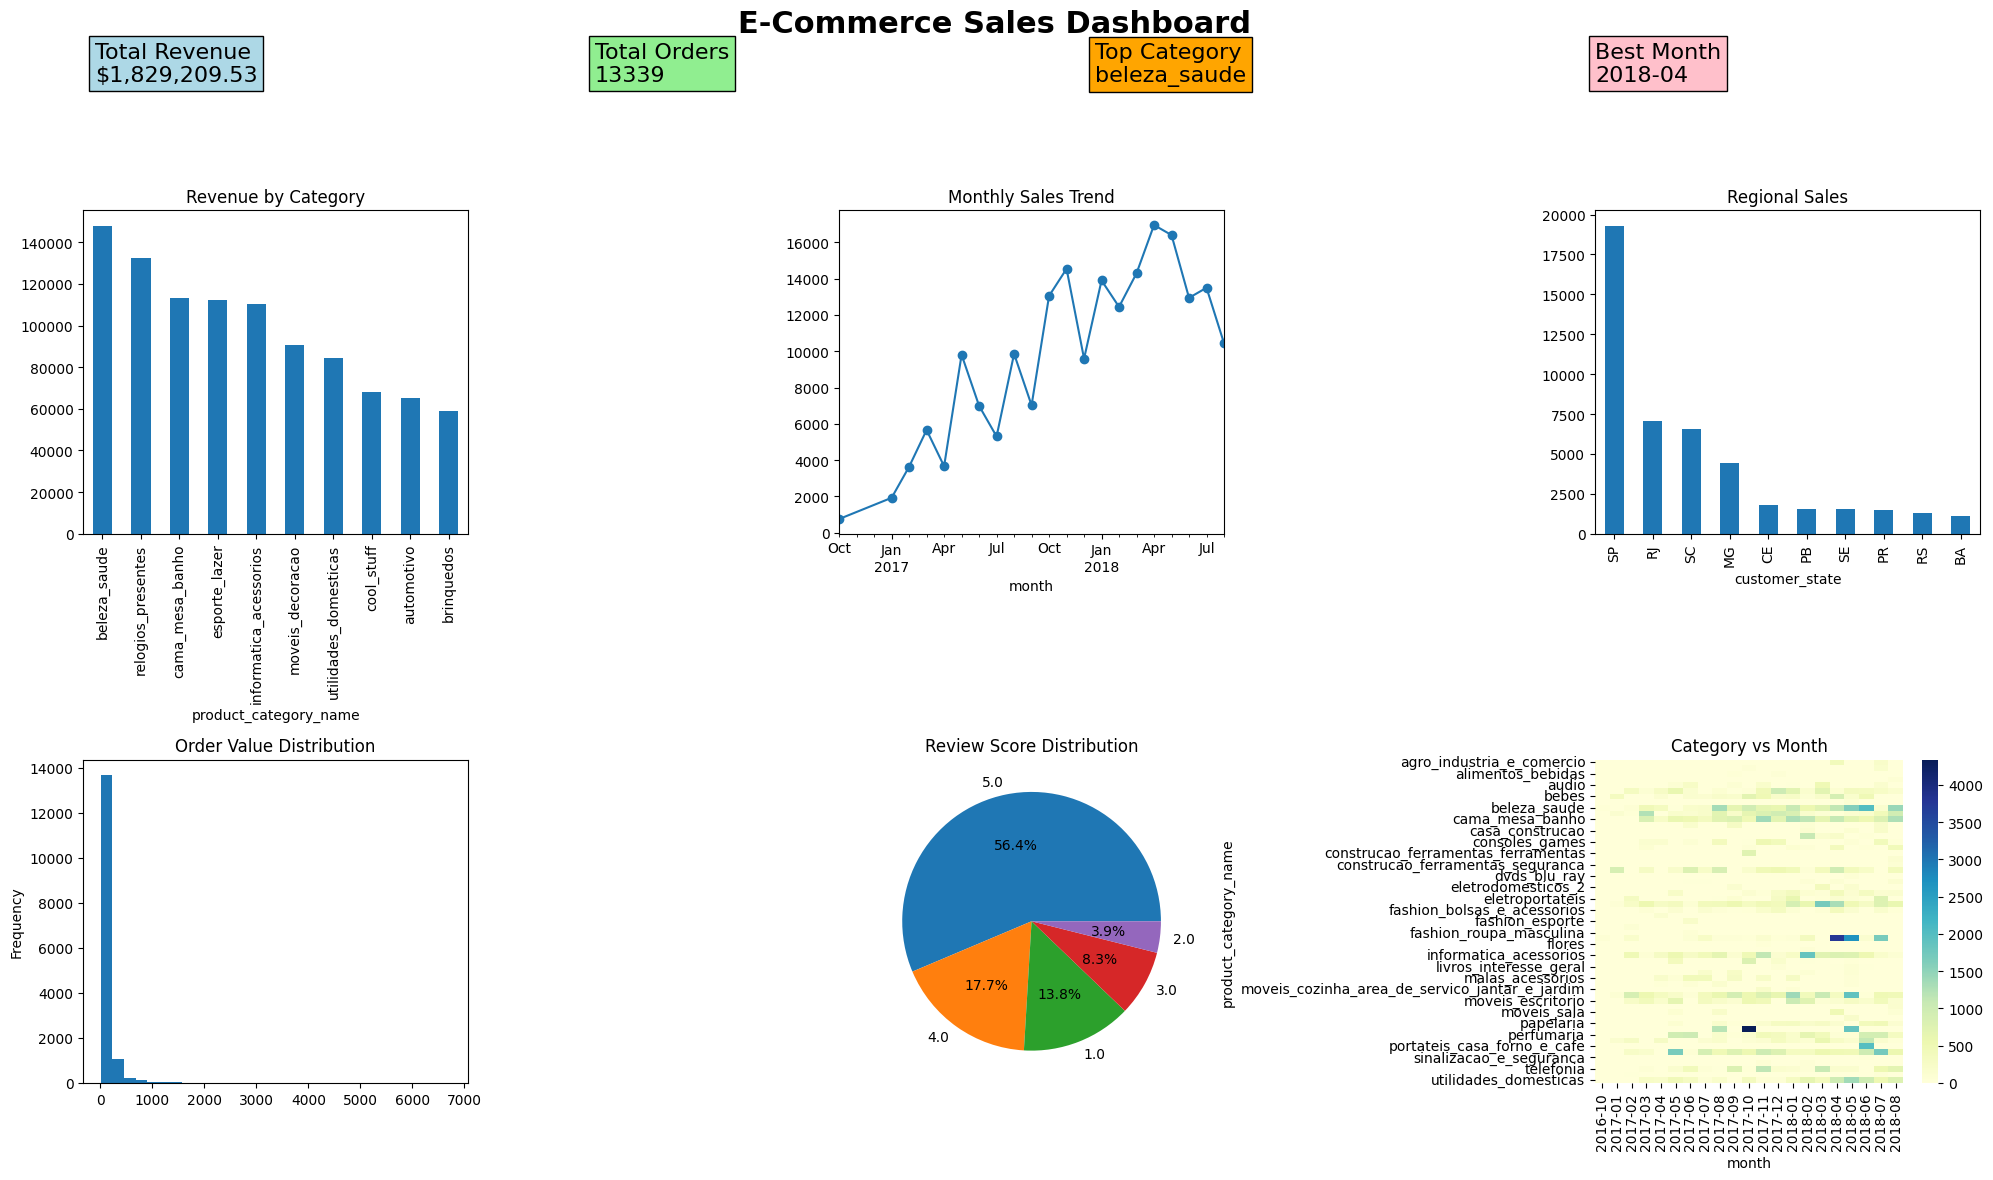

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(20,12))
fig.suptitle("E-Commerce Sales Dashboard", fontsize=22, fontweight='bold')

# KPI Cards
plt.figtext(0.05,0.92,f"Total Revenue\n${total_revenue:,.2f}",
            fontsize=16,bbox=dict(facecolor='lightblue'))

plt.figtext(0.30,0.92,f"Total Orders\n{total_orders}",
            fontsize=16,bbox=dict(facecolor='lightgreen'))

plt.figtext(0.55,0.92,f"Top Category\n{top_category}",
            fontsize=16,bbox=dict(facecolor='orange'))

plt.figtext(0.80,0.92,f"Best Month\n{best_month}",
            fontsize=16,bbox=dict(facecolor='pink'))

# Revenue by Category
plt.subplot(231)
category_revenue.head(10).plot(kind='bar') # Corrected from category_sales
plt.title("Revenue by Category")
plt.xticks(rotation=90)

# Monthly Sales
plt.subplot(232)
monthly_sales.plot(marker='o')
plt.title("Monthly Sales Trend")

# Regional Sales
plt.subplot(233)
regional_sales.head(10).plot(kind='bar') # Corrected from region_sales
plt.title("Regional Sales")

# Order Value Histogram
plt.subplot(234)
sales['price'].plot(kind='hist',bins=30) # Corrected from df['payment_value']
plt.title("Order Value Distribution")

# Review Scores
plt.subplot(235)
sales['review_score'].value_counts().plot(kind='pie',autopct='%1.1f%%') # Corrected from review_scores
plt.ylabel("")
plt.title("Review Score Distribution")

# Heatmap
plt.subplot(236)
sns.heatmap(
    heatmap_data.fillna(0),
    cmap='YlGnBu'
) # Corrected to use sns.heatmap for better visualization of DataFrame
plt.title("Category vs Month")

plt.tight_layout(rect=[0,0,1,0.88])

plt.savefig("Ecommerce_Dashboard.png",dpi=300,bbox_inches='tight')
plt.show()